# CabinGuard : détecter un AVC chez le conducteur (visage + voix)

**Projet :** une caméra et un micro surveillent le conducteur. Visage asymétrique ou voix altérée : alerte AVC.
**Données :** Toronto NeuroFace, vidéos de 11 personnes saines (label 0) et 14 post-AVC (label 1), filmées en clinique.
**Limite :** ce sont des personnes qui ont *déjà* eu un AVC, pas un AVC pendant la conduite.

## Le chemin (chaque étape utilise le résultat de la précédente)
```
VISAGE : points du visage -> mesures -> 4 modèles comparés -> le meilleur -> réglage (Grid search) -> modèle visage final
AUDIO  : voix -> MFCC / mel -> 4 modèles comparés -> le meilleur -> réglage -> modèle audio final
FUSION : modèle visage + modèle audio -> comparaison des fusions -> la meilleure
FINAL  : évaluation, fausses alarmes, explication (XAI), ressources
```

## Les chiffres
| Chiffre | Sens |
|---|---|
| **recall** | sur 100 post-AVC, combien détectés |
| **specificity** | sur 100 sains, combien laissés tranquilles |
| **precision** | quand le système alerte, combien de fois il a raison |
| **fausses alarmes /1000** | sur 1000 sains, combien déclenchent une alarme |
| **roc_auc** | qualité globale : 0,5 = pile ou face, 1 = parfait |

**Règle d'or :** on teste toujours sur des **personnes jamais vues** à l'entraînement (sinon le modèle reconnaît le visage au lieu de détecter l'AVC). Les chiffres sont donnés **par personne** : moyenne des notes de ses vidéos.

# 1. Préparation
Chemins du Drive partagé (cellule suivante), outils, et 3 petites fonctions : `scores` (recall, specificity, roc_auc), `noter` (écrit un tableau dans le journal d'expériences exigé par la consigne), `barres` (graphique, la ligne rouge est le hasard).

In [ ]:
# ===== 0. CHEMINS DU PROJET : exécuter cette cellule en premier =====
# Données : lues dans le dossier partagé « AI » (AI/datasets/), en lecture seule.
# Résultats : écrits dans VOTRE Drive, dans MyDrive/AI_outputs/<NOTEBOOK>.
#
# Une seule fois par personne, dans Google Drive (navigateur) :
#   « Partagés avec moi » > clic droit sur « AI » > Organiser > Ajouter un raccourci > « Mon Drive »
import glob, os
from pathlib import Path

NOTEBOOK = "stroke_detection"          # sous-dossier de sortie de ce notebook
BESOINS = ['stroke']              # datasets utilisés par ce notebook (clés de DATA ci-dessous)
AI_ROOT_MANUEL = None              # sur un PC uniquement, ex. r"G:\Mon Drive\AI" ; sinon laisser None

try:                               # Colab : monter Google Drive
    from google.colab import drive
    drive.mount("/content/drive")
    EN_COLAB = True
except ImportError:                # Jupyter sur un PC
    EN_COLAB = False


def trouver_racine_ai(nom="AI"):
    """Le dossier « AI » qui contient datasets/ et XAI/ (raccourci ou dossier dans Mon Drive, ou Drive partagé)."""
    ok = lambda p: (Path(p) / "datasets").is_dir() and (Path(p) / "XAI").is_dir()
    if AI_ROOT_MANUEL:
        return Path(AI_ROOT_MANUEL)
    for base in ("MyDrive", "Shareddrives"):
        for niveaux in range(4):                       # AI à la racine, puis jusqu'à 3 dossiers plus bas
            for p in sorted(glob.glob(f"/content/drive/{base}/{'*/' * niveaux}{nom}")):
                if ok(p):
                    return Path(p)
    for d in (Path.cwd(), *Path.cwd().parents):        # PC : notebook ouvert depuis le dossier AI synchronisé
        for p in (d, d / nom):
            if ok(p):
                return p
    raise FileNotFoundError(
        f"Dossier « {nom} » introuvable. Dans Google Drive : « Partagés avec moi » > clic droit sur « {nom} » "
        "> Organiser > Ajouter un raccourci > « Mon Drive », puis relancer cette cellule. "
        "Sur un PC : renseigner AI_ROOT_MANUEL.")


def _dossiers(racine, profondeur):
    """`racine` puis ses sous-dossiers, du moins profond au plus profond (dossiers cachés ignorés)."""
    niveau = [Path(racine)] if Path(racine).is_dir() else []
    for n in range(profondeur + 1):
        yield from niveau
        if n == profondeur:
            return
        suivant = []
        for d in niveau:
            try:
                with os.scandir(d) as entrees:
                    suivant += sorted(Path(e.path) for e in entrees
                                      if e.is_dir() and not e.name.startswith((".", "__")))
            except OSError:
                pass
        niveau = suivant


def trouver_fichier(noms, *dossiers, profondeur=3):
    """Premier fichier appelé `noms` (un nom ou une liste) dans `dossiers` ou leurs sous-dossiers."""
    noms = [noms] if isinstance(noms, str) else list(noms)
    for racine in dossiers:
        for d in _dossiers(racine, profondeur):
            for nom in noms:
                if (d / nom).is_file():
                    return d / nom
    raise FileNotFoundError(f"{' / '.join(noms)} introuvable dans : " + " ; ".join(map(str, dossiers)))


def trouver_dossier_contenant(sous_dossier, *dossiers, profondeur=3):
    """Premier dossier (dans `dossiers` ou leurs sous-dossiers) qui contient `sous_dossier`."""
    for racine in dossiers:
        for d in _dossiers(racine, profondeur):
            if (d / sous_dossier).is_dir():
                return d
    raise FileNotFoundError(f"Aucun dossier contenant {sous_dossier}/ dans : " + " ; ".join(map(str, dossiers)))


AI_ROOT = trouver_racine_ai()
DATASETS = AI_ROOT / "datasets"


def dataset(*mots, exact=False):
    """Sous-dossier de datasets/ dont le nom contient l'un des mots (ou vaut ce mot si exact=True), sans tenir compte des majuscules."""
    dossiers = sorted(d for d in DATASETS.iterdir() if d.is_dir())
    for mot in mots:
        for d in dossiers:
            if (d.name.lower() == mot.lower()) if exact else (mot.lower() in d.name.lower()):
                return d
    return DATASETS / mots[0]      # introuvable : signalé « MANQUANT » ci-dessous


DATA = {
    "seizure":     dataset("seizure"),                               # seizure dataset (release from github)
    "stroke":      dataset("neuroface", "stroke"),                   # NeuroFace Stroke dataset
    "cardiac":     dataset("heart"),                                 # heart diseasing dataset
    "cardiac_csv": dataset("cardiac_arrest_csv", "data", exact=True),  # CSV du modèle arrêt cardiaque
}

# Le dossier partagé est en lecture seule : chacun écrit ses résultats dans son propre Drive
SORTIES = (Path("/content/drive/MyDrive") if EN_COLAB else Path.cwd()) / "AI_outputs" / NOTEBOOK
SORTIES.mkdir(parents=True, exist_ok=True)

print("Dossier AI :", AI_ROOT)
for cle in BESOINS:
    print(f"  {'OK      ' if DATA[cle].is_dir() else 'MANQUANT'} DATA[{cle!r}] = {DATA[cle]}")
print("Sorties    :", SORTIES)

In [1]:
!pip -q install mediapipe opencv-python-headless librosa shap psutil nvidia-ml-py

import os, re, json, time, shutil, datetime, urllib.request, pickle, warnings
import numpy as np, pandas as pd, cv2, matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.model_selection import StratifiedGroupKFold, GridSearchCV
from sklearn.metrics import roc_auc_score, confusion_matrix, precision_score, accuracy_score, recall_score, roc_curve, ConfusionMatrixDisplay
warnings.filterwarnings("ignore")

ROOT = str(DATA["stroke"])   # données : AI/datasets/NeuroFace Stroke dataset (dossier partagé, lecture seule)
PROJ = str(SORTIES)          # résultats : MyDrive/AI_outputs/stroke_detection (votre Drive)
for d in ["data_processed/landmarks", "results", "logs"]:
    os.makedirs(f"{PROJ}/{d}", exist_ok=True)

def scores(y, proba, seuil=0.5):                           # -> [recall, specificity, roc_auc]
    y = np.asarray(y).astype(int)
    vn, fp, fn, vp = confusion_matrix(y, np.asarray(proba) >= seuil, labels=[0, 1]).ravel()
    return [round(vp / (vp + fn), 2), round(vn / (vn + fp), 2), round(roc_auc_score(y, proba), 2)]

LOG = f"{PROJ}/logs/experiments_log.csv"
def noter(tableau, etape):                                 # journal d'expériences : une ligne par ligne du tableau
    journal = pd.read_csv(LOG) if os.path.exists(LOG) else pd.DataFrame()
    nouvelles = pd.DataFrame([dict(date=datetime.datetime.now().strftime("%Y-%m-%d %H:%M"), dataset="NeuroFace",
                                   etape=etape, experience=nom, **{c: r[c] for c in ("recall", "specificity", "roc_auc") if c in r})
                              for nom, r in tableau.iterrows()])
    pd.concat([journal, nouvelles]).to_csv(LOG, index=False)

def barres(tableau, titre):                                # une barre par approche
    ax = tableau.roc_auc.sort_values().plot.barh(figsize=(8, 0.5 * len(tableau) + 1.5), color="tab:blue")
    ax.axvline(0.5, color="red", ls="--"); ax.set_xlim(0.4, 1)
    ax.set_xlabel("roc_auc (ligne rouge = hasard)"); ax.set_title(titre)
    plt.tight_layout(); plt.show()

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.5/41.5 MB 19.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.7/137.7 kB 13.4 MB/s eta 0:00:00
Mounted at /content/drive


# 2. Données et découpage par personne
- **Un tableau, une ligne par vidéo.** Le nom du fichier donne tout. Exemple : `OP01_02_BBP_NORMAL_color.avi` = personne `OP01` (pas de `N` au début : post-AVC), sous-tâche `NORMAL` (parole).
- **Parole** : `NORMAL`, `PA`, `PATAKA`. **Sans parole** : `BLOW`, `BROW`, `KISS`, `OPEN`, `SPREAD`. On retire `BIGSMILE` (inutilisable).
- **Découpage :** les *personnes* sont réparties en 5 groupes ; à chaque tour 4 groupes entraînent, 1 teste. On répète 3 fois (15 tests). Une personne n'est jamais des deux côtés.

**Attendu :** 77 vidéos saines (11 personnes), 102 post-AVC (14).

In [2]:
def nom_video(chemin):    # "OP01_02_BBP_NORMAL_color.avi" -> "OP01_02_BBP_NORMAL"
    return re.sub(r"(_color|_gt)$", "", os.path.splitext(os.path.basename(chemin))[0])

fichiers = [os.path.join(d, f) for d, _, fs in os.walk(ROOT, followlinks=True) for f in fs]
videos = [f for f in fichiers if f.lower().endswith(".avi")]
audios = {nom_video(f): f for f in fichiers if f.lower().endswith(".wav")}

# notes des 2 orthophonistes (servent seulement au test "experts" de la fusion)
slp = pd.concat([pd.read_excel(f) for f in fichiers if os.path.basename(f).startswith("SLP_Assessment") and f.endswith(".xlsx")])
slp["key"] = slp["File Name"].map(nom_video)
slp["Symmetry_mean"] = slp[["Symmetry (SLP1)", "Symmetry (SLP2)"]].mean(axis=1)
slp["Tot_mean"] = slp[["Tot (SLP1)", "Tot (SLP2)"]].mean(axis=1)

master = pd.DataFrame({"key": [nom_video(v) for v in videos], "video_path": videos})
master["subject"] = master.key.str.split("_").str[0]
master["subtask"] = master.key.str.split("_", n=3).str[3]
master["label"] = (~master.subject.str.startswith("N")).astype(int)      # N = sain (0), sinon AVC (1)
master["audio_path"] = master.key.map(audios)
master = master.drop_duplicates("key")
master = master[master.subtask != "BIGSMILE"]
master = master.merge(slp.drop_duplicates("key")[["key", "Symmetry_mean", "Tot_mean"]], on="key", how="left").reset_index(drop=True)
print(master.groupby("label").agg(videos=("key", "count"), personnes=("subject", "nunique")))

sujets = master.groupby("subject").label.first().reset_index()           # une ligne par personne
folds = []
for rep in range(3):
    for i, (tr, te) in enumerate(StratifiedGroupKFold(5, shuffle=True, random_state=42 + rep).split(sujets, sujets.label, sujets.subject)):
        folds.append(dict(repeat=rep, fold=i, train=sujets.subject.iloc[tr].tolist(), test=sujets.subject.iloc[te].tolist()))
assert all(not set(f["train"]) & set(f["test"]) for f in folds)          # aucune personne des deux côtés
print("Découpage OK :", len(folds), "tests, aucune fuite.")

       videos  personnes
label                   
0          77         11
1         102         14
Découpage OK : 15 tests, aucune fuite.


# 3. Les outils de test (utilisés partout)
- `construire(nom)` : fabrique un des 4 modèles (régression logistique, SVM, Random Forest, XGBoost).
- `predire` : entraîne sur les personnes « train », note les vidéos « test ». `note_par_personne` : moyenne des notes d'une personne. `evaluer` : 3 répétitions, rend recall / specificity / roc_auc par personne.
- `GRILLES` : les réglages à essayer pour chaque modèle. `regler` cherche les meilleurs (Grid search) **uniquement sur les personnes d'entraînement**. `tester_reglage` vérifie honnêtement si le réglage aide.

In [3]:
NOMS = ["Régression logistique", "SVM", "Random Forest", "XGBoost"]

def construire(nom, **reglages):                           # un modèle prêt à entraîner
    if nom == "Régression logistique": clf = LogisticRegression(max_iter=3000, class_weight="balanced")
    elif nom == "SVM": clf = SVC(probability=True, class_weight="balanced", random_state=42)
    elif nom == "Random Forest": clf = RandomForestClassifier(200, min_samples_leaf=3, class_weight="balanced_subsample", random_state=42)
    else: clf = XGBClassifier(n_estimators=150, max_depth=3, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8,
                              eval_metric="logloss", random_state=42)
    clf.set_params(**reglages)
    return Pipeline([("imp", SimpleImputer(strategy="median")),    # valeur manquante = médiane
                     ("sc", StandardScaler()), ("clf", clf)])

def predire(X, table, pli, fabrique):                      # entraîne sur 'train', note 'test'
    train, test = table.subject.isin(pli["train"]).values, table.subject.isin(pli["test"]).values
    if test.sum() == 0: return pd.DataFrame(columns=["subject", "y", "p"])
    modele = fabrique().fit(X[train], table.label.values[train])
    return pd.DataFrame({"subject": table.subject.values[test], "y": table.label.values[test],
                         "p": modele.predict_proba(X[test])[:, 1]})

def note_par_personne(predictions):                        # moyenne des notes de chaque personne
    tout = pd.concat(predictions); tout["p"] = tout["p"].astype(float)
    return tout.groupby("subject").agg(y=("y", "first"), p=("p", "mean"))

def evaluer(fabrique, X, table):                           # [recall, specificity, roc_auc] par personne, 3 répétitions
    res = []
    for rep in range(3):
        r = note_par_personne([predire(X, table, p, fabrique) for p in folds if p["repeat"] == rep])
        res.append(scores(r.y.values, r.p.values))
    return np.mean(res, axis=0).round(2)

# ---- Réglage : Grid search ----
GRILLES = {"Régression logistique": {"C": [0.01, 0.1, 1, 10], "class_weight": ["balanced", {0: 2, 1: 1}, {0: 3, 1: 1}]},
           "SVM": {"C": [0.1, 1, 10, 100], "gamma": [0.001, 0.01, 0.1, 1]},
           "Random Forest": {"max_depth": [3, 5, None], "min_samples_leaf": [1, 3, 5]},
           "XGBoost": {"max_depth": [2, 3, 4], "n_estimators": [100, 200]}}

def regler(nom, X, y, groupes):                            # meilleurs réglages, validation interne PAR PERSONNE
    cv = list(StratifiedGroupKFold(3, shuffle=True, random_state=0).split(X, y, groupes))
    grille = GridSearchCV(construire(nom), {"clf__" + k: v for k, v in GRILLES[nom].items()}, scoring="roc_auc", cv=cv)
    grille.fit(X, y)
    return {k.replace("clf__", ""): v for k, v in grille.best_params_.items()}

def tester_reglage(nom, X, table):
    # vérification sans triche (1 répétition) : le réglage est refait dans chaque entraînement
    sans, avec = [], []
    for pli in [f for f in folds if f["repeat"] == 0]:
        train = table.subject.isin(pli["train"]).values
        params = regler(nom, X[train], table.label.values[train], table.subject.values[train])
        sans.append(predire(X, table, pli, lambda: construire(nom)))
        avec.append(predire(X, table, pli, lambda: construire(nom, **params)))
    a, b = note_par_personne(sans), note_par_personne(avec)
    return scores(a.y.values, a.p.values), scores(b.y.values, b.p.values)

# 4. Points du visage : quel outil ?
En voiture, personne ne place les 68 points à la main : un outil doit le faire. NeuroFace contient ~1000 images où des humains ont placé les points : c'est notre vérité. On a comparé 3 outils (MediaPipe, FAN, dlib) à ces points.
**Erreur** = écart avec l'humain / distance entre les yeux. Exemple : 3 pixels d'écart pour 100 pixels entre les yeux = 0,03. Plus petit = mieux.
*(Ce test a été fait une fois et sauvegardé ; son code est dans la première version du notebook.)*

                      visage_detecte_pct  ms_par_image  mouth  brows   eyes
tool                                                                       
FAN (face-alignment)               100.0       168.122  0.043  0.049  0.028
MediaPipe                          100.0        16.078  0.030  0.057  0.021
dlib                                97.5       196.561  0.040  0.055  0.021


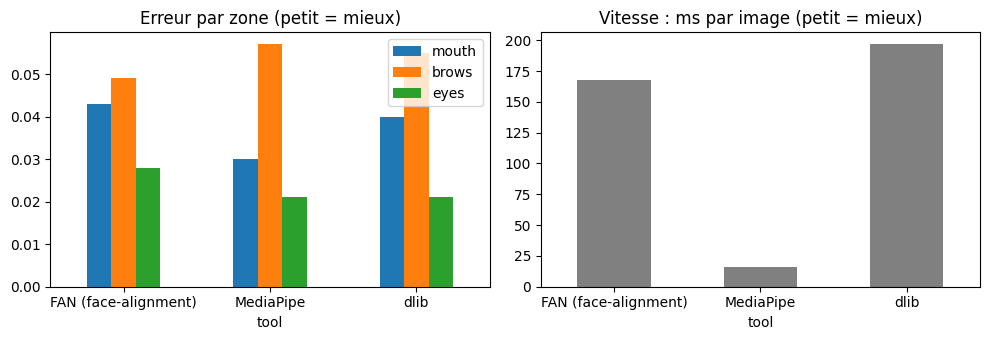

Outil le plus rapide : MediaPipe


In [4]:
# Comparaison faite une fois : cherchée dans vos résultats, sinon dans le dossier partagé AI/XAI/
outils = pd.read_csv(trouver_fichier("tools_comparison.csv", f"{PROJ}/results", AI_ROOT / "XAI", profondeur=4), index_col=0)
print(outils[["visage_detecte_pct", "ms_par_image", "mouth", "brows", "eyes"]].round(3))
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
outils[["mouth", "brows", "eyes"]].plot.bar(ax=ax[0], rot=0); ax[0].set_title("Erreur par zone (petit = mieux)")
outils["ms_par_image"].plot.bar(ax=ax[1], rot=0, color="gray"); ax[1].set_title("Vitesse : ms par image (petit = mieux)")
plt.tight_layout(); plt.savefig(f"{PROJ}/results/fig_outils.png", dpi=150); plt.show()
OUTIL = outils.ms_par_image.idxmin(); print("Outil le plus rapide :", OUTIL)

**Décision : MediaPipe.** Le plus rapide (16 ms contre 170 à 200 ms : indispensable en voiture), le meilleur sur la bouche (zone clé de l'AVC), trouve toujours le visage (100 %), et n'est pas moins précis sur les patients que sur les sains.
Il donne 478 points et 52 « blendshapes » (intensité d'expressions, ex. sourire gauche contre sourire droit). On le lance sur **toutes** les images de toutes les vidéos (une sur deux, ~25 images/s), pour s'entraîner avec des points **automatiques**, comme en voiture. Un fichier par vidéo ; si Colab coupe, relancer : les vidéos faites sont sautées (~30 min la première fois).

In [5]:
import mediapipe as mp
from mediapipe.tasks import python as mp_python
from mediapipe.tasks.python import vision
from tqdm.auto import tqdm

MODELE_MP = "/content/face_landmarker.task"
if not os.path.exists(MODELE_MP):
    urllib.request.urlretrieve("https://storage.googleapis.com/mediapipe-models/face_landmarker/face_landmarker/float16/1/face_landmarker.task", MODELE_MP)
detector = vision.FaceLandmarker.create_from_options(vision.FaceLandmarkerOptions(
    base_options=mp_python.BaseOptions(model_asset_path=MODELE_MP),
    running_mode=vision.RunningMode.IMAGE, num_faces=1, output_face_blendshapes=True))

def extraire(chemin_video, key, pas=2):
    sortie = f"{PROJ}/data_processed/landmarks/{key}.npz"
    if os.path.exists(sortie): return                      # déjà fait
    copie = f"/content/tmp_{key}.avi"; shutil.copy(chemin_video, copie)
    video = cv2.VideoCapture(copie); fps = video.get(cv2.CAP_PROP_FPS) or 30
    points, blend, temps, n = [], [], [], 0
    while True:
        ok, image = video.read()
        if not ok: break
        if n % pas == 0:                                   # une image sur deux
            r = detector.detect(mp.Image(image_format=mp.ImageFormat.SRGB, data=cv2.cvtColor(image, cv2.COLOR_BGR2RGB)))
            h, w = image.shape[:2]
            if r.face_landmarks:
                points.append([[p.x * w, p.y * h, p.z * w] for p in r.face_landmarks[0]])
                blend.append([b.score for b in r.face_blendshapes[0]])
            else:                                          # visage non trouvé : valeurs manquantes
                points.append(np.full((478, 3), np.nan)); blend.append(np.full(52, np.nan))
            temps.append(n / fps)
        n += 1
    video.release(); os.remove(copie)
    np.savez_compressed(sortie, pts=np.array(points, dtype=np.float32), blend=np.array(blend, dtype=np.float32), t=np.array(temps))

for ligne in tqdm(master.itertuples(), total=len(master)):
    extraire(ligne.video_path, ligne.key)
print("Fichiers créés :", len(os.listdir(f"{PROJ}/data_processed/landmarks")), "/", len(master))

  0%|          | 0/179 [00:00<?, ?it/s]

Fichiers créés : 179 / 179


# 5. Des points aux mesures d'asymétrie
Après un AVC, un côté du visage (surtout la bouche) peut s'affaisser. Exemple : le coin droit de la bouche est plus bas que le gauche.
1. **Aligner** : centrer sur les yeux, redresser la tête, diviser par la distance entre les yeux (une tête penchée ne doit pas paraître asymétrique).
2. **Asymétrie** : on trace la ligne du milieu (nez-menton), on retourne le côté droit comme dans un miroir, on mesure l'écart avec le côté gauche.
3. **Résumer chaque vidéo** en **37 chiffres** : valeur typique (`_med`), amplitude de mouvement (`_rom`), vitesse (`_speed`), écart gauche/droite des expressions (`bs_`).

Tableau : 179 vidéos x 37 mesures | sans parole : 104 vidéos


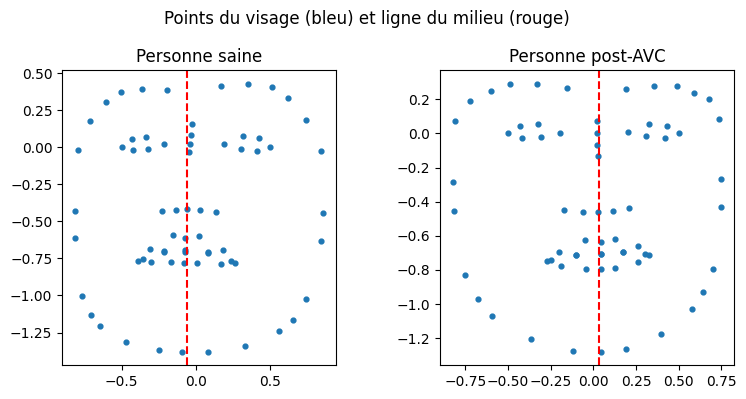

In [6]:
MP68 = [162,234,93,58,172,136,149,148,152,377,378,365,397,288,323,454,389,
        71,63,105,66,107,336,296,334,293,301,168,6,197,195,98,97,2,326,327,
        33,160,158,133,153,144,362,385,387,263,373,380,
        61,40,37,0,267,270,291,321,314,17,84,91,78,81,13,311,308,402,14,178]   # 68 points parmi les 478
BOUCHE = [(48,54),(49,53),(50,52),(59,55),(58,56),(60,64),(61,63),(67,65)]   # paires (gauche, droite)
SOURCILS = [(17,26),(18,25),(19,24),(20,23),(21,22)]
BLEND = {"brow_down": (1,2), "brow_outer_up": (4,5), "cheek_squint": (7,8), "eye_blink": (9,10), "eye_squint": (19,20),
         "mouth_dimple": (28,29), "mouth_frown": (30,31), "mouth_press": (36,37), "mouth_smile": (44,45),
         "mouth_stretch": (46,47), "mouth_upper_up": (48,49), "nose_sneer": (50,51), "mouth_lower_down": (34,35)}
AVEC_VITESSE = ["mouth_width", "mouth_open", "brow_to_eye", "corner_to_nose"]
dist = lambda a, b: np.linalg.norm(a - b, axis=-1)

def aligner(p):                                            # p : (images, 68 points, 2)
    centre = (p[:, 36] + p[:, 45]) / 2
    yeux = p[:, 45] - p[:, 36]
    angle = -np.arctan2(yeux[:, 1], yeux[:, 0])
    q = p - centre[:, None, :]
    x = q[..., 0] * np.cos(angle)[:, None] - q[..., 1] * np.sin(angle)[:, None]
    y = q[..., 0] * np.sin(angle)[:, None] + q[..., 1] * np.cos(angle)[:, None]
    return np.stack([x, y], -1) / np.linalg.norm(yeux, axis=1)[:, None, None]

def asymetrie(p, paires):                                  # point gauche contre miroir de son jumeau droit
    milieu = (p[:, 27, 0] + p[:, 8, 0]) / 2
    return np.mean([dist(p[:, g], np.stack([2 * milieu - p[:, d, 0], p[:, d, 1]], -1)) for g, d in paires], axis=0)

def mesures_par_image(p):
    oeil_g, oeil_d = p[:, 36:42].mean(1), p[:, 42:48].mean(1)
    milieu = (p[:, 27, 0] + p[:, 8, 0]) / 2
    return {"asym_mouth": asymetrie(p, BOUCHE), "asym_brows": asymetrie(p, SOURCILS),
            "mouth_tilt": np.abs(p[:, 54, 1] - p[:, 48, 1]),                  # coins de bouche à des hauteurs différentes
            "mouth_hshift": np.abs((p[:, 48, 0] + p[:, 54, 0]) / 2 - milieu), # bouche décalée sur le côté
            "corner_diff": np.abs(dist(p[:, 48], p[:, 33]) - dist(p[:, 54], p[:, 33])),
            "brow_diff": np.abs(dist(p[:, 19], oeil_g) - dist(p[:, 24], oeil_d)),
            "brow_to_eye": (dist(p[:, 19], oeil_g) + dist(p[:, 24], oeil_d)) / 2,
            "corner_to_nose": (dist(p[:, 48], p[:, 33]) + dist(p[:, 54], p[:, 33])) / 2,
            "mouth_width": dist(p[:, 48], p[:, 54]), "mouth_open": dist(p[:, 62], p[:, 66])}

def resumer(p, blend, t):                                  # une ligne de chiffres pour toute la vidéo
    out = {}
    for nom, v in mesures_par_image(p).items():
        out[f"{nom}_med"] = np.nanmedian(v)                                   # valeur typique
        out[f"{nom}_rom"] = np.nanpercentile(v, 95) - np.nanpercentile(v, 5)  # amplitude
        if nom in AVEC_VITESSE: out[f"{nom}_speed"] = np.nanmedian(np.abs(np.diff(v)) / np.diff(t))
    for nom, (g, d) in BLEND.items():
        out[f"bs_{nom}_asym"] = abs(np.nanpercentile(blend[:, g], 90) - np.nanpercentile(blend[:, d], 90))
    return out

def charger(key):
    z = np.load(f"{PROJ}/data_processed/landmarks/{key}.npz")
    return aligner(z["pts"][:, MP68, :2].astype(float)), z["blend"], z["t"]

mesures = pd.DataFrame([resumer(*charger(k)) for k in master.key]); mesures.insert(0, "key", master.key.values)
data = master[["key", "subject", "label", "subtask"]].merge(mesures, on="key").reset_index(drop=True)
colonnes = [c for c in mesures.columns if c != "key"]
PAROLE = ["NORMAL", "PA", "PATAKA"]
sans_parole = data[~data.subtask.isin(PAROLE)].reset_index(drop=True)
print("Tableau :", len(data), "vidéos x", len(colonnes), "mesures | sans parole :", len(sans_parole), "vidéos")

fig, ax = plt.subplots(1, 2, figsize=(8, 4))               # illustration : visage aligné, tâche KISS
for a, lab, titre in zip(ax, [0, 1], ["Personne saine", "Personne post-AVC"]):
    p, _, _ = charger(data[(data.label == lab) & (data.subtask == "KISS")].key.iloc[0])
    f = p[np.where(~np.isnan(p[:, 0, 0]))[0][10]]
    a.scatter(f[:, 0], -f[:, 1], s=12); a.axvline((f[27, 0] + f[8, 0]) / 2, color="red", ls="--")
    a.set_title(titre); a.set_aspect("equal")
plt.suptitle("Points du visage (bleu) et ligne du milieu (rouge)"); plt.tight_layout(); plt.show()

# 6. Visage : quel modèle ?
On compare les 4 modèles sur les mesures du visage, avec le même test. On regarde aussi si les **tâches sans parole** sont meilleures que **toutes les tâches** (sourire ou baiser font de grands mouvements : l'asymétrie se voit mieux ; en parlant, le visage bouge peu, et la parole sera traitée par l'audio).
**Le meilleur modèle (plus haut roc_auc, tâches sans parole) est retenu automatiquement pour la suite.**

=== VISAGE : 4 modèles (tâches sans parole, par personne) ===
                        recall  specificity  roc_auc  roc_auc (toutes tâches)
Régression logistique    0.79         0.88     0.86                     0.65
SVM                      0.93         0.61     0.83                     0.75
Random Forest            0.81         0.61     0.83                     0.72
XGBoost                  0.86         0.58     0.82                     0.68


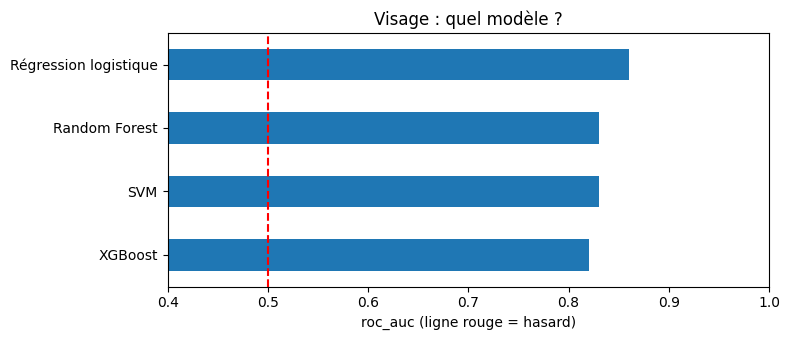


Modèle visage retenu : Régression logistique


In [7]:
X_sp, y_sp = sans_parole[colonnes].values, sans_parole.label.values
lignes = {}
for nom in NOMS:
    sp = evaluer(lambda: construire(nom), X_sp, sans_parole)               # tâches sans parole
    toutes = evaluer(lambda: construire(nom), data[colonnes].values, data)  # toutes les tâches
    lignes[nom] = list(sp) + [toutes[2]]
tab_visage = pd.DataFrame(lignes, index=["recall", "specificity", "roc_auc", "roc_auc (toutes tâches)"]).T
print("=== VISAGE : 4 modèles (tâches sans parole, par personne) ===\n", tab_visage)
barres(tab_visage, "Visage : quel modèle ?")
noter(tab_visage, "visage : 4 modèles")
MEILLEUR = tab_visage.roc_auc.idxmax()
print("\nModèle visage retenu :", MEILLEUR)

**Comment lire :** une ligne par modèle. `roc_auc` départage ; `recall` et `specificity` montrent le type d'erreur (rater un AVC ou fausse alarme). Si `roc_auc (toutes tâches)` est plus bas que `roc_auc`, retirer la parole était bon.
**Limite :** 25 personnes, donc un écart de moins de 0,03 est du bruit.

# 7. Visage : régler le meilleur modèle (Grid search)
**Idée :** chaque modèle a des réglages (ex. `C` : sévérité du modèle). **Grid search** essaie toutes les combinaisons d'une petite grille et garde la meilleure. Pour la régression logistique, la grille inclut aussi le **poids des classes** : faire peser 2 fois plus une erreur sur un sain réduit les fausses alarmes.

**Pourquoi seulement Grid search ?** Ces modèles s'entraînent en une fraction de seconde : essayer toutes les combinaisons coûte quelques secondes. Random search et Optuna servent quand un essai est très long (deep learning). Ici ils ne feraient pas mieux.

**Sans triche :** le réglage est cherché uniquement sur les personnes d'entraînement. On compare « sans réglage » et « avec réglage » sur des personnes jamais vues. S'il n'aide pas, on garde les réglages par défaut.

In [8]:
debut = time.time()
sans_r, avec_r = tester_reglage(MEILLEUR, X_sp, sans_parole)
PARAMS_VISAGE = regler(MEILLEUR, X_sp, y_sp, sans_parole.subject.values)
print(f"Grid search sur {MEILLEUR} : {time.time() - debut:.0f} s")
reglage = pd.DataFrame({"sans réglage": sans_r, "avec Grid search": avec_r}, index=["recall", "specificity", "roc_auc"]).T
print(reglage)
if avec_r[2] < sans_r[2]:
    PARAMS_VISAGE = {}; print("Le réglage n'aide pas : réglages par défaut gardés.")
visage_final = lambda: construire(MEILLEUR, **PARAMS_VISAGE)
print("\nMODÈLE VISAGE FINAL :", MEILLEUR, "| réglages :", PARAMS_VISAGE or "par défaut")
noter(reglage, "visage : réglage")

Grid search sur Régression logistique : 3 s
                  recall  specificity  roc_auc
sans réglage        0.79         0.82     0.86
avec Grid search    0.57         0.82     0.85
Le réglage n'aide pas : réglages par défaut gardés.

MODÈLE VISAGE FINAL : Régression logistique | réglages : par défaut


# 8. Audio : de la voix aux chiffres
Un son est une courbe impossible à comparer telle quelle. On en fait une **image** : le **spectrogramme** (temps en horizontal, fréquence en vertical, couleur = intensité). Le **mel-spectrogramme** est la même image avec des fréquences à l'échelle de l'oreille. Les **MFCC** en sont un résumé : 13 chiffres par instant décrivant le timbre de la voix.
Un modèle veut une ligne de chiffres par audio : on résume chaque mesure par sa moyenne et son écart-type (MFCC : 26 chiffres, mel : 80 chiffres).

On garde les tâches de parole qui ont un fichier audio. On compare MFCC et mel : si le mel ne marche pas, il n'est pas retenu.

Vidéos de parole : 75 | avec audio : 65 | personnes : 24


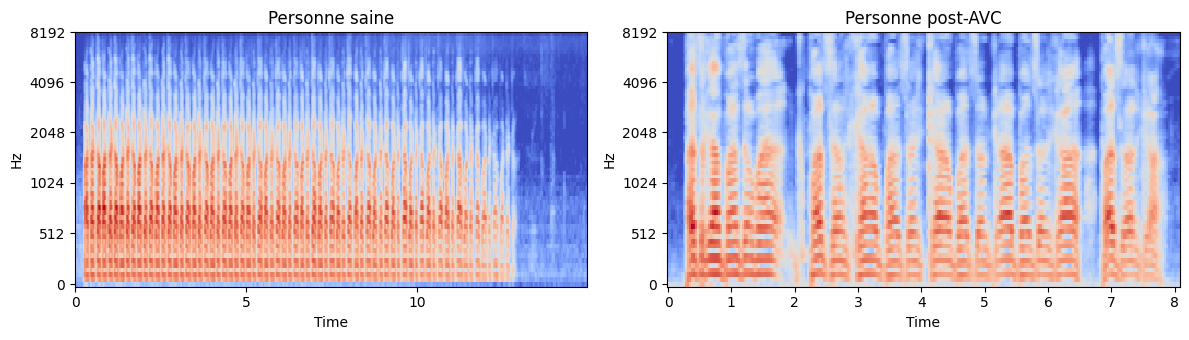

{'MFCC': (65, 26), 'Mel-spectrogramme': (65, 80)}


In [9]:
import librosa, librosa.display

parole = master[master.subtask.isin(PAROLE)]
audio = parole[parole.audio_path.notna()].reset_index(drop=True)
print("Vidéos de parole :", len(parole), "| avec audio :", len(audio), "| personnes :", audio.subject.nunique())

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))            # voir l'idée : sain contre post-AVC (PATAKA)
for a, lab, titre in zip(ax, [0, 1], ["Personne saine", "Personne post-AVC"]):
    ligne = audio[(audio.label == lab) & (audio.subtask == "PATAKA")].iloc[0]
    son, sr = librosa.load(ligne.audio_path, sr=16000, duration=15)
    mel = librosa.power_to_db(librosa.feature.melspectrogram(y=son, sr=sr, n_mels=64))
    librosa.display.specshow(mel, sr=sr, x_axis="time", y_axis="mel", ax=a); a.set_title(titre)
plt.tight_layout(); plt.savefig(f"{PROJ}/results/fig_spectrogrammes.png", dpi=150); plt.show()

def f_mfcc(son, sr):                                       # 13 MFCC -> moyenne + écart-type = 26 chiffres
    m = librosa.feature.mfcc(y=son, sr=sr, n_mfcc=13)
    return np.r_[m.mean(axis=1), m.std(axis=1)]
def f_mel(son, sr):                                        # 40 bandes -> moyenne + écart-type = 80 chiffres
    m = librosa.power_to_db(librosa.feature.melspectrogram(y=son, sr=sr, n_mels=40))
    return np.r_[m.mean(axis=1), m.std(axis=1)]

sons = [librosa.load(p, sr=16000, mono=True, duration=30)[0] for p in audio.audio_path]
X_audio_fam = {"MFCC": np.array([f_mfcc(s, 16000) for s in sons]), "Mel-spectrogramme": np.array([f_mel(s, 16000) for s in sons])}
print({k: v.shape for k, v in X_audio_fam.items()})

# 9. Audio : quel modèle, puis réglage
Même méthode que le visage : 2 familles de mesures × 4 modèles, même test. La meilleure combinaison est retenue **automatiquement**, puis réglée par Grid search (avec la même vérification sans triche).

=== AUDIO : 2 familles x 4 modèles (par personne) ===
                                            recall  specificity  roc_auc
MFCC | Régression logistique                 0.84         0.70     0.80
MFCC | SVM                                   0.91         0.63     0.78
MFCC | Random Forest                         0.93         0.43     0.61
MFCC | XGBoost                               0.86         0.40     0.56
Mel-spectrogramme | Régression logistique    0.84         0.43     0.70
Mel-spectrogramme | SVM                      0.91         0.40     0.68
Mel-spectrogramme | Random Forest            0.86         0.33     0.69
Mel-spectrogramme | XGBoost                  0.91         0.40     0.72


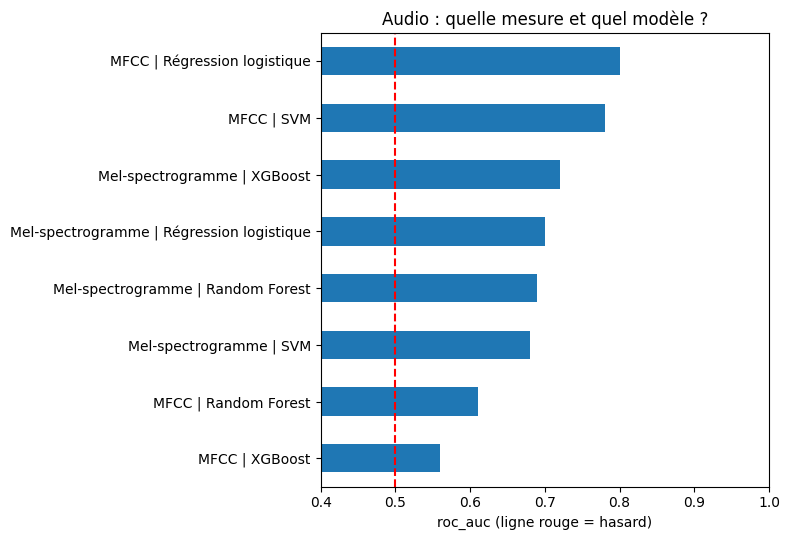


Audio retenu : MFCC + Régression logistique

                   recall  specificity  roc_auc
sans réglage        0.86          0.7     0.79
avec Grid search    0.86          0.6     0.76
Le réglage n'aide pas : réglages par défaut gardés.
MODÈLE AUDIO FINAL : MFCC + Régression logistique | réglages : par défaut


In [10]:
lignes = {f"{fam} | {nom}": evaluer(lambda: construire(nom), Xa, audio) for fam, Xa in X_audio_fam.items() for nom in NOMS}
tab_audio = pd.DataFrame(lignes, index=["recall", "specificity", "roc_auc"]).T
print("=== AUDIO : 2 familles x 4 modèles (par personne) ===\n", tab_audio)
barres(tab_audio, "Audio : quelle mesure et quel modèle ?")
noter(tab_audio, "audio : familles x modèles")
FAMILLE, MODELE_AUDIO = tab_audio.roc_auc.idxmax().split(" | ")
X_aud = X_audio_fam[FAMILLE]; y_aud = audio.label.values
print("\nAudio retenu :", FAMILLE, "+", MODELE_AUDIO)

sans_r, avec_r = tester_reglage(MODELE_AUDIO, X_aud, audio)
PARAMS_AUDIO = regler(MODELE_AUDIO, X_aud, y_aud, audio.subject.values)
reglage_a = pd.DataFrame({"sans réglage": sans_r, "avec Grid search": avec_r}, index=["recall", "specificity", "roc_auc"]).T
print("\n", reglage_a)
if avec_r[2] < sans_r[2]:
    PARAMS_AUDIO = {}; print("Le réglage n'aide pas : réglages par défaut gardés.")
audio_final = lambda: construire(MODELE_AUDIO, **PARAMS_AUDIO)
print("MODÈLE AUDIO FINAL :", FAMILLE, "+", MODELE_AUDIO, "| réglages :", PARAMS_AUDIO or "par défaut")
noter(reglage_a, "audio : réglage")

**Comment lire :** si les MFCC dépassent le mel, le mel (résumé par une moyenne, il perd l'information dans le temps) n'est pas utile et n'est pas retenu. Limite : environ 65 audios sur 24 personnes : encourageant mais fragile. Pas de réseau de neurones sur les spectrogrammes : avec si peu d'audios il apprendrait par cœur.

# 10. Fusion visage + audio
**Idée :** on a un modèle visage et un modèle audio. Chacun donne une note entre 0 et 1. On combine, **par personne**. Exemple : note visage 0,7 et note audio 0,5 donnent 0,6 (fusion 50/50).

**Pourquoi par personne ?** Le visage marche sur les tâches sans parole, l'audio sur les tâches de parole : une même vidéo n'a presque jamais les deux.
**Quelles données sont fusionnables ?** Seulement visage et audio de NeuroFace (même enregistrement). Les autres jeux du projet (montre connectée, signaux ICU) concernent d'autres personnes : fusion possible seulement au niveau du système.

| Approche | Principe |
|---|---|
| Visage seul, Audio seul | références |
| **Tardive 50/50** et **70/30** | chaque modèle note, puis moyenne (70 % visage : poids fixé à l'avance, car le visage est plus fiable seul) |
| **Précoce** | on colle les chiffres visage et audio dans un seul modèle |
| **Tardive 70/30 + repli** | si l'audio manque, on garde le visage seul (cas voiture, toutes les personnes) |
| + notes d'experts | on ajoute les notes des orthophonistes. **Borne haute, pas déployable** : absentes en voiture |

Un second tableau vérifie si un autre modèle ferait mieux en fusion (réglages par défaut).

=== FUSION (par personne) ===
                                  recall  specificity  roc_auc  \
Visage seul                        0.79         0.87     0.85   
Audio seul                         0.84         0.70     0.80   
Tardive 50/50                      0.84         0.63     0.90   
Tardive 70/30                      0.84         0.83     0.91   
Précoce                            0.84         0.63     0.83   
Tardive 70/30 + repli              0.84         0.85     0.92   
+ notes d'experts (borne haute)    0.98         0.91     0.99   

                                 fausses alarmes /1000  
Visage seul                                      130.0  
Audio seul                                       300.0  
Tardive 50/50                                    370.0  
Tardive 70/30                                    170.0  
Précoce                                          370.0  
Tardive 70/30 + repli                            150.0  
+ notes d'experts (borne haute)                  

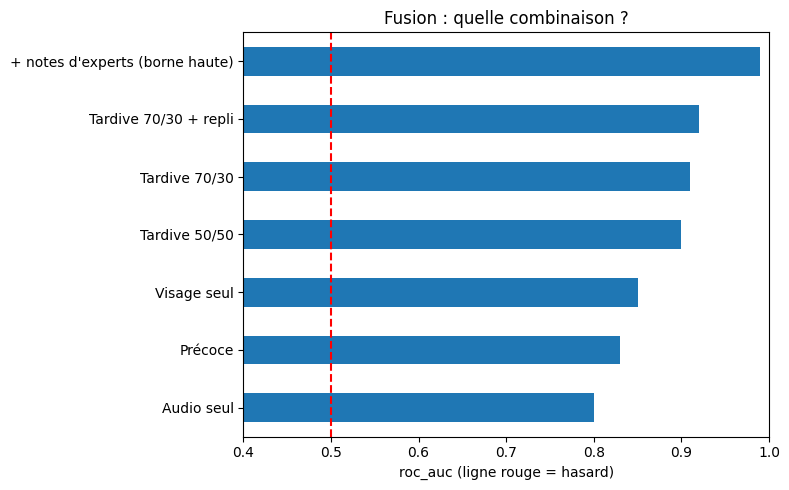


=== AUTRES MODÈLES EN FUSION (roc_auc, réglages par défaut) ===
                        Tardive 70/30  Précoce
Régression logistique           0.91     0.83
SVM                             0.91     0.82
Random Forest                   0.86     0.76
XGBoost                         0.85     0.64


In [11]:
exp = master.set_index("key")[["Symmetry_mean", "Tot_mean"]]               # notes d'experts
X_precoce = np.hstack([data.set_index("key").loc[audio.key, colonnes].values, X_aud])   # visage + audio collés

def tester_fusion(fab_v, fab_a, fab_p, avec_experts=False):
    Xv, Xa, Xp = X_sp, X_aud, X_precoce
    if avec_experts:                                       # notes d'experts ajoutées (train ET test)
        Xv = np.hstack([Xv, exp.loc[sans_parole.key].values])
        Xa = np.hstack([Xa, exp.loc[audio.key].values]); Xp = np.hstack([Xp, exp.loc[audio.key].values])
    res = {n: [] for n in ["Visage seul", "Audio seul", "Tardive 50/50", "Tardive 70/30", "Précoce", "Tardive 70/30 + repli"]}
    notes = []
    for rep in range(3):
        plis = [f for f in folds if f["repeat"] == rep]
        V = note_par_personne([predire(Xv, sans_parole, p, fab_v) for p in plis])
        A = note_par_personne([predire(Xa, audio, p, fab_a) for p in plis])
        P = note_par_personne([predire(Xp, audio, p, fab_p) for p in plis])
        commun = V.index.intersection(A.index); y = V.loc[commun, "y"].values        # personnes avec visage ET audio
        t70 = 0.7 * V.loc[commun, "p"] + 0.3 * A.loc[commun, "p"]
        res["Visage seul"].append(scores(y, V.loc[commun, "p"].values))
        res["Audio seul"].append(scores(y, A.loc[commun, "p"].values))
        res["Tardive 50/50"].append(scores(y, ((V.loc[commun, "p"] + A.loc[commun, "p"]) / 2).values))
        res["Tardive 70/30"].append(scores(y, t70.values))
        res["Précoce"].append(scores(P.y.values, P.p.values))
        repli = V.p.copy(); repli.loc[commun] = t70                                  # repli : visage seul si pas d'audio
        res["Tardive 70/30 + repli"].append(scores(V.y.values, repli.values)); notes.append(repli)
    return {n: np.mean(r, axis=0).round(2) for n, r in res.items()}, pd.concat(notes, axis=1).mean(axis=1)

res, note_finale = tester_fusion(visage_final, audio_final, visage_final)
res_exp, _ = tester_fusion(visage_final, audio_final, visage_final, avec_experts=True)
fusion = pd.DataFrame(res, index=["recall", "specificity", "roc_auc"]).T
fusion.loc["+ notes d'experts (borne haute)"] = res_exp["Tardive 70/30 + repli"]
fusion["fausses alarmes /1000"] = ((1 - fusion.specificity) * 1000).round()
print("=== FUSION (par personne) ===\n", fusion)
barres(fusion, "Fusion : quelle combinaison ?")
noter(fusion, "fusion")

autres = {}
for nom in NOMS:                                           # un autre modèle ferait-il mieux ? (réglages par défaut)
    f = lambda n=nom: construire(n)
    r, _ = tester_fusion(f, f, f)
    autres[nom] = [r["Tardive 70/30"][2], r["Précoce"][2]]
print("\n=== AUTRES MODÈLES EN FUSION (roc_auc, réglages par défaut) ===\n",
      pd.DataFrame(autres, index=["Tardive 70/30", "Précoce"]).T)

**Comment lire :** la fusion est utile si **Tardive** dépasse **Visage seul** et **Audio seul** (le visage et la voix ne se trompent pas sur les mêmes personnes, donc la moyenne corrige leurs erreurs). Si **Précoce** est plus faible, c'est attendu : coller beaucoup de chiffres pour ~65 vidéos noie le modèle. La ligne « notes d'experts » est très haute car ces notes décrivent déjà l'asymétrie : ce n'est pas une amélioration du modèle.
**Décision :** fusion tardive 70/30 avec repli (la meilleure architecture déployable, et la seule qui marche sans audio). Le second tableau confirme ou non le choix du modèle.

# 11. Évaluation finale et fausses alarmes
On évalue la fusion retenue sur les 25 personnes. Pour une alarme de voiture, une fausse alarme est dangereuse (panique, freinage). Les leviers utilisés **dans les étapes précédentes** : le poids des classes (inclus dans la grille de réglage) et le choix du modèle.

**Le seuil** (0,5 par défaut) n'est **pas** choisi sur ces 25 personnes : le choisir en regardant le résultat le rendrait trop beau (comme choisir ses réponses après avoir vu la correction). Le tableau des seuils est donné pour information. Un seuil d'alarme d'urgence plus haut demanderait de nouvelles personnes pour être validé honnêtement.

**Intervalle :** avec 25 personnes, un chiffre seul ne suffit pas. On refait 1000 fois le calcul en tirant des personnes au hasard avec remise ; la fourchette où tombent 95 % des résultats dit si le chiffre est stable (« 0,90 entre 0,75 et 1,00 » = peu certain).

Personnes évaluées : 25 | post-AVC : 14 | sains : 11
Poids des classes retenu pour le visage : balanced (par défaut)

=== MÉTRIQUES (seuil 0,5) ===
 recall                    0.86
specificity               0.91
precision                 0.92
fausses alarmes /1000    90.91
roc_auc                   0.94
(accuracy)                0.88
dtype: float64

=== EFFET DU SEUIL (information, pas un choix) ===
     recall  specificity  precision  fausses alarmes /1000
0.3    1.00         0.45       0.70                 545.45
0.4    1.00         0.64       0.78                 363.64
0.5    0.86         0.91       0.92                  90.91
0.6    0.71         0.91       0.91                  90.91
0.7    0.57         0.91       0.89                  90.91

roc_auc : 0.94 (fourchette 95 % : 0.82 à 1.00) | recall : 0.86 (fourchette 95 % : 0.67 à 1.00)


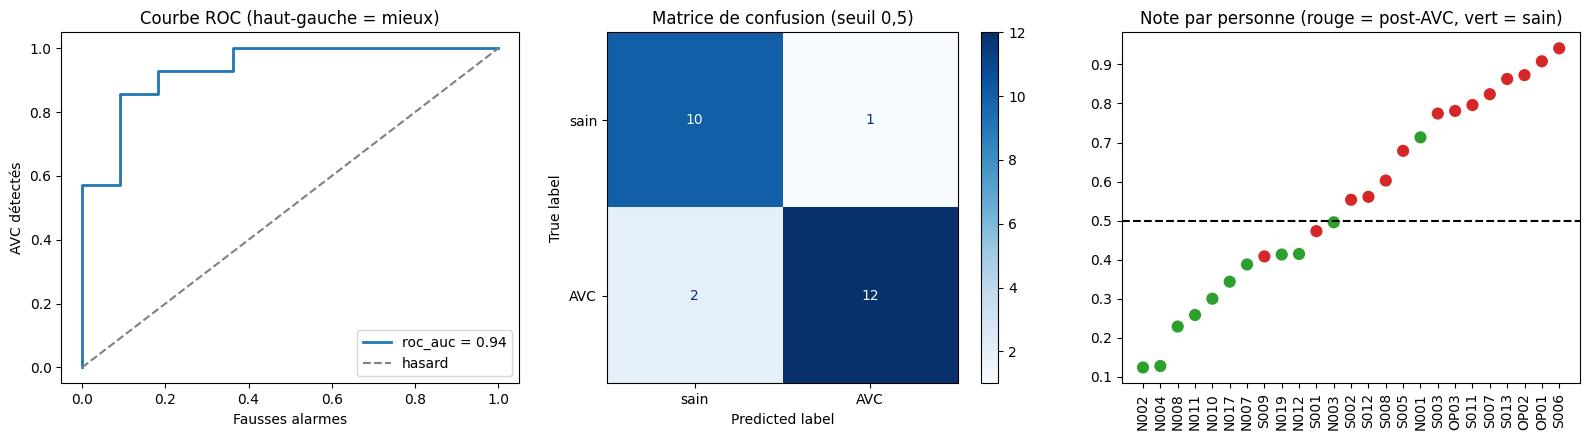


=== PERSONNES MAL CLASSÉES ===
          vrai (0 sain, 1 AVC)  note
subject                            
S009                        1  0.41
S001                        1  0.47
N001                        0  0.71


In [12]:
y_vrai = sujets.set_index("subject").label.loc[note_finale.index].astype(int)
note, y = note_finale.values, y_vrai.values
print("Personnes évaluées :", len(y), "| post-AVC :", y.sum(), "| sains :", (1 - y).sum())
print("Poids des classes retenu pour le visage :", PARAMS_VISAGE.get("class_weight", "balanced (par défaut)"))

def metriques(y, note, seuil=0.5):
    pred = (note >= seuil).astype(int)
    vn, fp, fn, vp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return {"recall": vp / (vp + fn), "specificity": vn / (vn + fp), "precision": precision_score(y, pred, zero_division=0),
            "fausses alarmes /1000": 1000 * fp / (vn + fp), "roc_auc": roc_auc_score(y, note), "(accuracy)": accuracy_score(y, pred)}
m = pd.Series(metriques(y, note)).round(2)
print("\n=== MÉTRIQUES (seuil 0,5) ===\n", m)
print("\n=== EFFET DU SEUIL (information, pas un choix) ===")
print(pd.DataFrame({s: pd.Series(metriques(y, note, s))[["recall", "specificity", "precision", "fausses alarmes /1000"]]
                    for s in [0.3, 0.4, 0.5, 0.6, 0.7]}).T.round(2))

rng = np.random.default_rng(42); auc_b, rec_b = [], []
for _ in range(1000):
    i = rng.integers(0, len(y), len(y))                    # personnes tirées avec remise
    if y[i].min() == y[i].max(): continue
    auc_b.append(roc_auc_score(y[i], note[i])); rec_b.append(recall_score(y[i], note[i] >= 0.5))
f95 = lambda v: f"{np.percentile(v, 2.5):.2f} à {np.percentile(v, 97.5):.2f}"
print(f"\nroc_auc : {m['roc_auc']} (fourchette 95 % : {f95(auc_b)}) | recall : {m['recall']} (fourchette 95 % : {f95(rec_b)})")

fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
fpr, tpr, _ = roc_curve(y, note)
ax[0].plot(fpr, tpr, lw=2, label=f"roc_auc = {m['roc_auc']}"); ax[0].plot([0, 1], [0, 1], "--", color="gray", label="hasard")
ax[0].set_xlabel("Fausses alarmes"); ax[0].set_ylabel("AVC détectés"); ax[0].set_title("Courbe ROC (haut-gauche = mieux)"); ax[0].legend()
ConfusionMatrixDisplay.from_predictions(y, (note >= 0.5).astype(int), ax=ax[1], cmap="Blues", display_labels=["sain", "AVC"])
ax[1].set_title("Matrice de confusion (seuil 0,5)")
ordre = note_finale.sort_values()
ax[2].scatter(range(len(ordre)), ordre.values, s=60, c=["tab:red" if y_vrai[s] == 1 else "tab:green" for s in ordre.index])
ax[2].axhline(0.5, color="black", ls="--"); ax[2].set_xticks(range(len(ordre))); ax[2].set_xticklabels(ordre.index, rotation=90)
ax[2].set_title("Note par personne (rouge = post-AVC, vert = sain)")
plt.tight_layout(); plt.savefig(f"{PROJ}/results/fig_evaluation_finale.png", dpi=150); plt.show()

erreurs = pd.DataFrame({"vrai (0 sain, 1 AVC)": y_vrai, "note": note_finale})
mal = erreurs[(erreurs.note >= 0.5).astype(int) != erreurs.iloc[:, 0]]
print("\n=== PERSONNES MAL CLASSÉES ===\n", mal.round(2).sort_values("note"))
noter(pd.DataFrame([m[["recall", "specificity", "roc_auc"]]], index=["fusion finale"]), "évaluation finale")

**Comment lire :** le recall dit combien d'AVC sont détectés, « fausses alarmes /1000 » combien de sains déclenchent une alarme, la fourchette dit à quel point on peut se fier au chiffre. La matrice montre **qui** se trompe : la case « vrai AVC, prédit sain » est la plus grave. Le graphique de droite montre chaque personne : les rouges devraient être à droite de la ligne, les verts à gauche.
**Limites :** 25 personnes (fourchette large : prometteur, pas démontré) ; les choix ont été faits sur les mêmes données (légèrement optimiste) ; en voiture l'AVC est très rare, donc la precision réelle serait bien plus basse.

LE MODÈLE ET LES EXPERTS SONT-ILS D'ACCORD ?

1) Sain ou malade ?         accord = 0.56  -> OUI, ils vont dans le même sens
2) Qui est le plus malade ? accord = -0.17  -> NON, le modèle ne mesure pas la gravité
(accord : 1 = identique, 0 = aucun lien, négatif = à l'envers)

LES ERREURS DU MODÈLE :
- N001 : vraiment sain, le modèle dit AVC (note 0.71), les experts donnent 1.2 sur 5
- S001 : vraiment AVC, le modèle dit sain (note 0.47), les experts donnent 2.6 sur 5
- S009 : vraiment AVC, le modèle dit sain (note 0.41), les experts donnent 2.9 sur 5


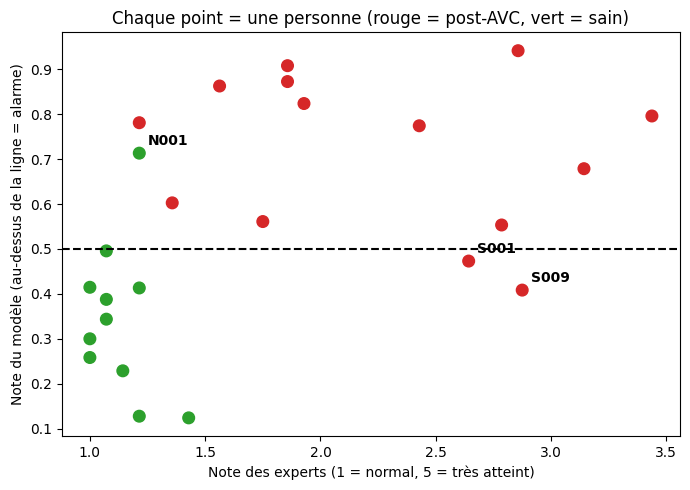

In [18]:
from scipy.stats import spearmanr

sym = master.groupby("subject").Symmetry_mean.mean().loc[note_finale.index]   # note des experts (1 = normal, 5 = très atteint)
pa = y_vrai[y_vrai == 1].index                                                  # les personnes post-AVC

r_tous, _ = spearmanr(note_finale, sym)
r_avc, _ = spearmanr(note_finale[pa], sym[pa])

print("LE MODÈLE ET LES EXPERTS SONT-ILS D'ACCORD ?\n")
print(f"1) Sain ou malade ?         accord = {r_tous:.2f}  ->",
      "OUI, ils vont dans le même sens" if r_tous > 0.4 else "NON")
print(f"2) Qui est le plus malade ? accord = {r_avc:.2f}  ->",
      "OUI" if r_avc > 0.4 else "NON, le modèle ne mesure pas la gravité")
print("(accord : 1 = identique, 0 = aucun lien, négatif = à l'envers)\n")

print("LES ERREURS DU MODÈLE :")
for s in mal.index:
    vrai = "AVC" if y_vrai[s] == 1 else "sain"
    modele = "AVC" if note_finale[s] >= 0.5 else "sain"
    print(f"- {s} : vraiment {vrai}, le modèle dit {modele} (note {note_finale[s]:.2f}), les experts donnent {sym[s]:.1f} sur 5")

# Graphique : une personne = un point
plt.figure(figsize=(7, 5))
plt.scatter(sym, note_finale, s=70, c=["tab:red" if y_vrai[s] == 1 else "tab:green" for s in sym.index])
plt.axhline(0.5, color="black", ls="--")
for s in mal.index:
    plt.annotate(s, (sym[s], note_finale[s]), textcoords="offset points", xytext=(6, 6), fontweight="bold")
plt.xlabel("Note des experts (1 = normal, 5 = très atteint)")
plt.ylabel("Note du modèle (au-dessus de la ligne = alarme)")
plt.title("Chaque point = une personne (rouge = post-AVC, vert = sain)")
plt.tight_layout(); plt.savefig(f"{PROJ}/results/fig_experts_vs_modele.png", dpi=150); plt.show()

# 12. Explicabilité (XAI) : pourquoi le modèle répond « AVC » ?
La méthode dépend du modèle :

| Modèle | Méthode | Ce qu'elle montre |
|---|---|---|
| Régression logistique | **Coefficients** | poids de chaque mesure (positif = vers AVC) |
| Random Forest, XGBoost | **SHAP** | contribution moyenne de chaque mesure |
| SVM et tout modèle | **Permutation** | on mélange une mesure au hasard : si la qualité chute, le modèle s'en sert |
| Fusion | **Ablation** | retirer le visage ou l'audio : voir les lignes « Visage seul » et « Audio seul » du tableau de fusion |

On l'applique au **modèle final** du visage et de l'audio : la permutation (valable pour tous), plus la méthode propre au modèle retenu.
**Limite :** montre ce que le modèle *utilise*, pas ce qui est médicalement vrai ; les mesures corrélées se partagent l'importance.

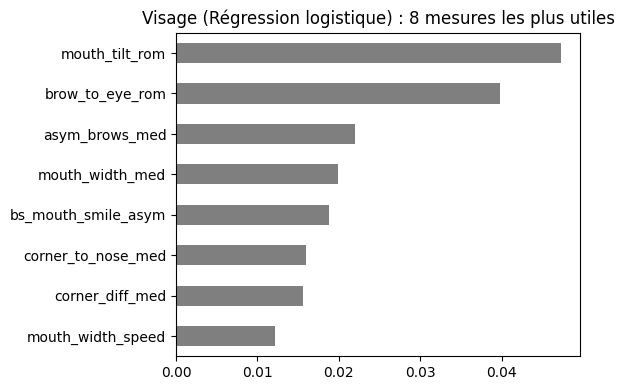

Coefficients (rouge = vers AVC, bleu = vers sain) :


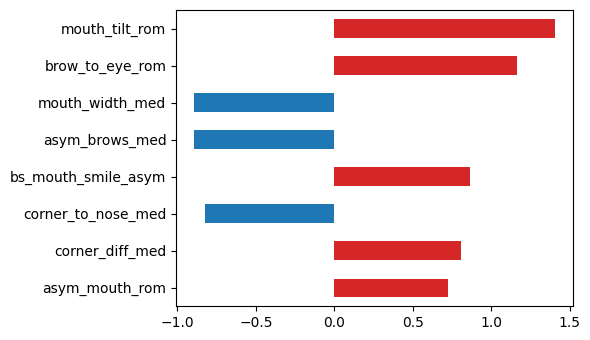

In [14]:
import shap
from sklearn.inspection import permutation_importance

# Visage : permutation (on mélange une mesure, on regarde si la qualité chute)
modele_v = visage_final().fit(X_sp, y_sp)
imp_v = pd.Series(permutation_importance(modele_v, X_sp, y_sp, scoring="roc_auc", n_repeats=20, random_state=0).importances_mean, index=colonnes)
imp_v.sort_values().tail(8).plot.barh(figsize=(6, 4), color="tab:gray", title=f"Visage ({MEILLEUR}) : 8 mesures les plus utiles")
plt.tight_layout(); plt.savefig(f"{PROJ}/results/fig_xai.png", dpi=150); plt.show()
imp_v.to_csv(f"{PROJ}/results/xai_visage.csv")

# Méthode propre au modèle retenu
if MEILLEUR == "Régression logistique":
    coef = pd.Series(modele_v[-1].coef_[0], index=colonnes)
    print("Coefficients (rouge = vers AVC, bleu = vers sain) :")
    c = coef.reindex(coef.abs().sort_values(ascending=False).index).head(8)[::-1]
    c.plot.barh(color=["tab:red" if v > 0 else "tab:blue" for v in c], figsize=(6, 3.5)); plt.tight_layout(); plt.show()
elif MEILLEUR in ("Random Forest", "XGBoost"):
    v = shap.TreeExplainer(modele_v[-1]).shap_values(modele_v[:-1].transform(X_sp))
    v = v[1] if isinstance(v, list) else (v[:, :, 1] if v.ndim == 3 else v)
    pd.Series(np.abs(v).mean(axis=0), index=colonnes).sort_values().tail(8).plot.barh(figsize=(6, 3.5), title="SHAP"); plt.tight_layout(); plt.show()

**Comment lire :** les mesures en tête sont celles dont le modèle a le plus besoin. Pour le visage, on s'attend à la bouche (asymétrie, inclinaison, hauteur des coins) : c'est cohérent avec la littérature, car après un AVC la bouche est la zone la plus touchée. Si l'explication correspond à la médecine, c'est un bon signe ; sinon, il faut s'en méfier.

# 13. Consommation de ressources
Pour chaque modèle : temps d'entraînement, **latence** (temps pour une prédiction), **CPU** (100 % = un cœur), **RAM** pic, taille du modèle, mémoire **GPU**. Outils : `psutil` (CPU, RAM), `tracemalloc` (pic de mémoire Python), `pynvml` (GPU), `time` (latence). On mesure aussi l'extraction (MediaPipe, MFCC), car elle fait partie de la chaîne en voiture. Nos modèles tournent sur CPU : le GPU sera à ~0, c'est normal.

In [15]:
import psutil, tracemalloc
proc = psutil.Process()
try:
    import pynvml; pynvml.nvmlInit(); gpu = pynvml.nvmlDeviceGetHandleByIndex(0)
    gpu_mo = lambda: pynvml.nvmlDeviceGetMemoryInfo(gpu).used / 1e6
except Exception:
    gpu_mo = lambda: np.nan                                # pas de GPU connecté

def chrono(f):                                             # -> (résultat, secondes, % CPU)
    c0, t0 = sum(proc.cpu_times()[:2]), time.perf_counter()
    r = f(); t = time.perf_counter() - t0
    return r, t, 100 * (sum(proc.cpu_times()[:2]) - c0) / max(t, 1e-9)

def mesurer(nom, fabrique, X, y):
    g0 = gpu_mo(); tracemalloc.start()
    modele, t_train, _ = chrono(lambda: fabrique().fit(X, y))
    ram = tracemalloc.get_traced_memory()[1] / 1e6; tracemalloc.stop()
    _, t_inf, cpu = chrono(lambda: [modele.predict_proba(X[:1]) for _ in range(200)])     # une vidéo à la fois
    return {"modèle": nom, "entraînement (s)": round(t_train, 2), "latence (ms)": round(t_inf / 200 * 1000, 2),
            "CPU (%)": round(cpu), "RAM pic (Mo)": round(ram, 1), "taille (Ko)": round(len(pickle.dumps(modele)) / 1e3),
            "GPU (Mo)": round(gpu_mo() - g0, 1)}

lignes = [mesurer(f"{n} (visage)", lambda: construire(n), X_sp, y_sp) for n in NOMS]
lignes.append(mesurer(f"{MODELE_AUDIO} ({FAMILLE}, audio)", audio_final, X_aud, y_aud))

# extraction : MediaPipe (par image) et audio (par fichier de 30 s)
video = cv2.VideoCapture(master.video_path.iloc[0]); images = []
for _ in range(50):
    ok, im = video.read()
    if not ok: break
    images.append(mp.Image(image_format=mp.ImageFormat.SRGB, data=cv2.cvtColor(im, cv2.COLOR_BGR2RGB)))
video.release()
g0, ram0 = gpu_mo(), proc.memory_info().rss / 1e6
_, t, cpu = chrono(lambda: [detector.detect(i) for i in images])
lignes.append({"modèle": "MediaPipe (par image)", "latence (ms)": round(t / len(images) * 1000, 1), "CPU (%)": round(cpu),
               "RAM pic (Mo)": round(proc.memory_info().rss / 1e6 - ram0, 1), "GPU (Mo)": round(gpu_mo() - g0, 1)})
f_audio = f_mfcc if FAMILLE == "MFCC" else f_mel
_, t, cpu = chrono(lambda: [f_audio(sons[0], 16000) for _ in range(20)])
lignes.append({"modèle": f"{FAMILLE} (par audio)", "latence (ms)": round(t / 20 * 1000, 1), "CPU (%)": round(cpu)})

perf = pd.DataFrame(lignes).set_index("modèle")
print(perf.to_string()); perf.to_csv(f"{PROJ}/results/benchmark_ressources.csv")

                                     entraînement (s)  latence (ms)  CPU (%)  RAM pic (Mo)  taille (Ko)  GPU (Mo)
modèle                                                                                                           
Régression logistique (visage)                   0.02          0.92      169           0.2          3.0       0.0
SVM (visage)                                     0.02          0.86       99           0.2         31.0       0.0
Random Forest (visage)                           2.84         12.43      100           0.4        405.0       0.0
XGBoost (visage)                                 0.11          1.17      201           0.2        156.0       0.0
Régression logistique (MFCC, audio)              0.03          0.94      148           0.1          2.0       0.0
MediaPipe (par image)                             NaN         16.20      109          13.2          NaN       0.0
MFCC (par audio)                                  NaN         25.80      194           N

**Comment lire :** la colonne importante pour la voiture est la **latence**. Les modèles de décision répondent en une fraction de milliseconde ; c'est l'**extraction des points (MediaPipe)** qui coûte le plus. **Limite :** mesures faites sur Colab, pas sur une carte embarquée ; la RAM de MediaPipe est une estimation.

# 14. Résumé automatique et conclusion
Cette dernière cellule relit toutes les décisions prises par le notebook.

In [16]:
print("OUTIL VISAGE   : MediaPipe (le plus rapide, meilleur sur la bouche)")
print(f"MODÈLE VISAGE  : {MEILLEUR} | réglages : {PARAMS_VISAGE or 'par défaut'} | tâches sans parole")
print(f"MODÈLE AUDIO   : {MODELE_AUDIO} sur {FAMILLE} | réglages : {PARAMS_AUDIO or 'par défaut'}")
print("FUSION         : tardive 70 % visage / 30 % audio, repli sur le visage si pas d'audio")
print(f"RÉSULTAT       : recall {m['recall']} | specificity {m['specificity']} | fausses alarmes {m['fausses alarmes /1000']:.0f}/1000 sains"
      f" | roc_auc {m['roc_auc']} (fourchette {f95(auc_b)})")

OUTIL VISAGE   : MediaPipe (le plus rapide, meilleur sur la bouche)
MODÈLE VISAGE  : Régression logistique | réglages : par défaut | tâches sans parole
MODÈLE AUDIO   : Régression logistique sur MFCC | réglages : par défaut
FUSION         : tardive 70 % visage / 30 % audio, repli sur le visage si pas d'audio
RÉSULTAT       : recall 0.86 | specificity 0.91 | fausses alarmes 91/1000 sains | roc_auc 0.94 (fourchette 0.82 à 1.00)


## Conclusion
Une chaîne simple et reliée : MediaPipe place les points, le meilleur modèle est choisi puis réglé pour le visage et pour l'audio, la fusion tardive les combine, et le résultat est évalué sur des personnes jamais vues, avec fourchette d'incertitude, explication et coût en ressources.